In [2]:
import pandas as pd
import numpy as np

In [3]:
X=pd.read_csv('data_for_model_traning.csv')
y=pd.read_csv('target_data.csv')

In [4]:
X=X.drop(X.columns[0],axis=1)

In [5]:
y=y.drop(y.columns[0],axis=1)

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

### we have done stratifed split as our data is imblanced

In [8]:
y_train.value_counts(normalize=1)

target
0         0.991884
1         0.008116
Name: proportion, dtype: float64

In [9]:
y_test.value_counts(normalize=1)

target
0         0.991886
1         0.008114
Name: proportion, dtype: float64

# MODEL 1 (LOGESTIC REGRESSION)

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [11]:
scaler=StandardScaler()
scaler_1=StandardScaler()

In [12]:
X_train_s=scaler.fit_transform(X_train)

In [13]:
y_train_s=scaler_1.fit_transform(y_train)

In [14]:
y_test_s=scaler_1.transform(y_test)

In [15]:
X_test_s=scaler.transform(X_test)

In [16]:
X_train_s

array([[-0.21562465, -0.09665953, -0.18092876, ..., -1.39262355,
        -0.39652059, -1.48924808],
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.92184129,
         1.63643786,  0.29385208],
       [-0.21562465, -0.09665953, -0.18092876, ..., -1.39262355,
        -1.41299981,  0.16648779],
       ...,
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.15035301,
        -0.9047602 , -0.7250623 ],
       [-0.21562465, -0.09665953, -0.18092876, ...,  1.69332957,
         0.61995864,  0.42121638],
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.15035301,
        -1.41299981, -0.7250623 ]], shape=(1409340, 7))

In [17]:
X_train.describe()

,views,add_to_cart,unique_item_viewed,session_duration_min,month,day,hour
count,1.409340e+06,1.409340e+06,1.409340e+06,1.409340e+06,1.409340e+06,1.409340e+06,1.409340e+06
mean,1.512387e+00,3.953695e-02,1.323294e+00,1.755779e+00,6.805113e+00,2.780184e+00,1.269282e+01
std,2.376291e+00,4.090332e-01,1.786858e+00,8.407695e+00,1.296196e+00,1.967577e+00,7.851497e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00,0.000000e+00,0.000000e+00
25%,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,4.000000e+00
50%,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,7.000000e+00,3.000000e+00,1.600000e+01
75%,1.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,8.000000e+00,4.000000e+00,2.000000e+01
max,4.170000e+02,1.140000e+02,3.890000e+02,7.284041e+02,9.000000e+00,6.000000e+00,2.300000e+01


In [18]:
model=LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

In [19]:
X_train_s

array([[-0.21562465, -0.09665953, -0.18092876, ..., -1.39262355,
        -0.39652059, -1.48924808],
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.92184129,
         1.63643786,  0.29385208],
       [-0.21562465, -0.09665953, -0.18092876, ..., -1.39262355,
        -1.41299981,  0.16648779],
       ...,
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.15035301,
        -0.9047602 , -0.7250623 ],
       [-0.21562465, -0.09665953, -0.18092876, ...,  1.69332957,
         0.61995864,  0.42121638],
       [-0.21562465, -0.09665953, -0.18092876, ...,  0.15035301,
        -1.41299981, -0.7250623 ]], shape=(1409340, 7))

In [20]:
y_train

,target
618262,0
868507,0
732963,0
1465375,0
1760271,0
...,...
729838,0
43086,0
1339933,0
860062,0


In [21]:
model.fit(X_train_s,y_train)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [22]:
y_pred=model.predict(X_test_s)

In [23]:
y_prob=model.predict_proba(X_test)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [24]:
y_prob

array([[9.32599015e-01, 6.74009853e-02],
       [7.99422903e-01, 2.00577097e-01],
       [2.10002124e-05, 9.99979000e-01],
       ...,
       [9.41305803e-01, 5.86941972e-02],
       [7.97792250e-01, 2.02207750e-01],
       [7.89202569e-01, 2.10797431e-01]], shape=(352335, 2))

In [25]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(352335,))

## Evalulating the model

In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [27]:
print(
    classification_report(y_test,y_pred)
)

              precision    recall  f1-score   support

           0       1.00      0.96      0.98    349476
           1       0.15      0.86      0.25      2859

    accuracy                           0.96    352335
   macro avg       0.57      0.91      0.62    352335
weighted avg       0.99      0.96      0.97    352335



In [28]:
roc_auc =roc_auc_score(
    y_test,
    y_pred
)
print(roc_auc)

0.9096342343482986


#### means overall goodfit of the model over the data

In [29]:
pr_auc =average_precision_score(
    y_test,
    y_pred
)
pr_auc

0.12927523103276406

#### 0.525*100=5.25% our purches rate predicted by the model but actual purches rate is 0.81% 

In [30]:
cm = confusion_matrix(
    y_test,
    y_pred
)
cm

array([[335454,  14022],
       [   402,   2457]])

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [32]:
accuracy_score(y_test,y_pred)

0.9590616884499127

In [33]:
y_test.mean()*100

target    0.811444
dtype: float64

#### actual purches rate

# MODEL 2 (RANDOM FOREST)

In [34]:
from sklearn.ensemble import RandomForestClassifier

In [35]:
model_2=RandomForestClassifier(n_estimators=300,min_samples_split=5,class_weight='balanced',random_state=42,n_jobs=-1,min_samples_leaf=2)

In [36]:
model_2.fit(X_train_s,y_train)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [37]:
y_pred_2=model_2.predict(X_test_s)

In [38]:
# accuracy_score(y_pred_2,y_test)
# classification_report(y_pred_2,y_test)
# confusion_matrix(y_pred_2,y_test)
# roc_auc_score(y_pred_2,y_test)
# average_precision_score(y_pred_2,y_test)

In [39]:
accuracy_score(y_test,y_pred_2)

0.9928335249123703

In [40]:
print(classification_report(y_test,y_pred_2))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00    349476
           1       0.54      0.77      0.64      2859

    accuracy                           0.99    352335
   macro avg       0.77      0.88      0.82    352335
weighted avg       0.99      0.99      0.99    352335



In [41]:
confusion_matrix(y_test,y_pred_2)

array([[347597,   1879],
       [   646,   2213]])

In [42]:
roc_auc_score(y_test,y_pred_2)

0.8843351242682539

In [43]:
average_precision_score(y_test,y_pred_2)

0.42044680645472454

# MODEL 3 (GRADIENT BOOSTING)

In [44]:
from sklearn.ensemble import GradientBoostingClassifier

In [45]:
from sklearn.utils.class_weight import compute_sample_weight

In [46]:
sample_weights=compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

In [47]:
model_3=GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42,
)

In [48]:
model_3.fit(X_train_s,y_train,sample_weight=sample_weights)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``,

In [87]:
y_pred_3=model_3.predict(X_test_s)

In [88]:
accuracy_score(y_test,y_pred_3)


0.9658847403749272

In [51]:
confusion_matrix(y_pred_3,y_test)

array([[318528,    569],
       [ 30948,   2290]])

In [52]:
roc_auc_score(y_test,y_pred_3)

0.8562119630652671

In [53]:
average_precision_score(y_test,y_pred_3)

0.05680005201262631

In [54]:
print(classification_report(y_test,y_pred_3))

              precision    recall  f1-score   support

           0       1.00      0.91      0.95    349476
           1       0.07      0.80      0.13      2859

    accuracy                           0.91    352335
   macro avg       0.53      0.86      0.54    352335
weighted avg       0.99      0.91      0.95    352335



# MODEL 4 (XGBoost)

In [55]:
!pip install xgboost

In [56]:
from xgboost import XGBClassifier

In [57]:
y_train.value_counts()

target
0         1397902
1           11438
Name: count, dtype: int64

In [58]:
scale_pos_weight=y_train.value_counts()[0]/y_train.value_counts()[1]

In [59]:
model_4=XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    n_jobs=-1
)

In [60]:
model_4.fit(X_train_s,y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [95]:
y_pred_4=model_4.predict(X_test_s)

In [96]:
y_pred_4

array([0, 0, 0, ..., 0, 0, 0], shape=(352335,))

In [97]:
y_test

,target
80950,0
1516844,0
291187,0
1153070,0
980819,0
...,...
179648,0
20775,0
744186,0
1659258,0


In [98]:
accuracy_score(y_test,y_pred_4)

0.9705053429264763

In [99]:
print(classification_report(y_test,y_pred_4))


              precision    recall  f1-score   support

           0       1.00      0.97      0.98    349476
           1       0.21      0.97      0.35      2859

    accuracy                           0.97    352335
   macro avg       0.61      0.97      0.67    352335
weighted avg       0.99      0.97      0.98    352335



In [100]:
confusion_matrix(y_test,y_pred_4)

array([[339182,  10294],
       [    98,   2761]])

In [101]:
roc_auc_score(y_test,y_pred_4)

0.9681333764066645

In [102]:
average_precision_score(y_test,y_pred_4)

0.20451860523825752

# COMPARING THE MODELS

In [103]:
 from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(model, X_test, y_test):

    # Predictions
    y_pred = model.predict(X_test)

    # Probability of purchase (class = 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

In [104]:
results = {}

results["Logistic Regression"] = evaluate_model(
    model,
    X_test_s,
    y_test
)

results["Random Forest"] = evaluate_model(
    model_2,
    X_test_s,
    y_test
)

results["Gradient Boosting"] = evaluate_model(
    model_3,
    X_test_s,
    y_test
)

results["XGBoost"] = evaluate_model(
    model_4,
    X_test_s,
    y_test
)

In [105]:
results

{'Logistic Regression': {'Accuracy': 0.9590616884499127,
  'Precision': 0.1490988530857455,
  'Recall': 0.8593913955928646,
  'F1 Score': 0.2541110766366739,
  'ROC-AUC': 0.9775762660724763,
  'PR-AUC': 0.33105291682079324},
 'Random Forest': {'Accuracy': 0.9928335249123703,
  'Precision': 0.5408113391984359,
  'Recall': 0.7740468695348024,
  'F1 Score': 0.6367429146885341,
  'ROC-AUC': 0.9879849738640937,
  'PR-AUC': 0.6742013733465763},
 'Gradient Boosting': {'Accuracy': 0.9658847403749272,
  'Precision': 0.1885073104386263,
  'Recall': 0.9695697796432319,
  'F1 Score': 0.31564563880665,
  'ROC-AUC': 0.9944589695634303,
  'PR-AUC': 0.6250377056878232},
 'XGBoost': {'Accuracy': 0.9705053429264763,
  'Precision': 0.21148985063194178,
  'Recall': 0.9657222805176635,
  'F1 Score': 0.3469900716350383,
  'ROC-AUC': 0.9950707499241427,
  'PR-AUC': 0.6974043746441718}}

## Model Performance Comparison


In [107]:
results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
XGBoost,0.970505,0.211490,0.965722,0.346990,0.995071,0.697404
Random Forest,0.992834,0.540811,0.774047,0.636743,0.987985,0.674201
Gradient Boosting,0.965885,0.188507,0.969570,0.315646,0.994459,0.625038
Logistic Regression,0.959062,0.149099,0.859391,0.254111,0.977576,0.331053


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but GradientBoostingClassifier was fitted without feature names
  warnings.warn(


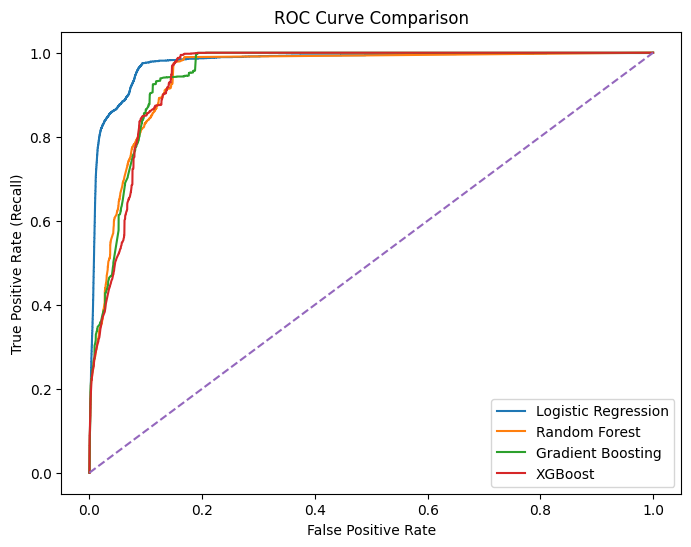

In [108]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt


lr_prob = model.predict_proba(X_test_s)[:, 1]
rf_prob = model_2.predict_proba(X_test)[:, 1]
gb_prob = model_3.predict_proba(X_test)[:, 1]
xgb_prob = model_4.predict_proba(X_test)[:, 1]


lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)


plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label="Logistic Regression")
plt.plot(rf_fpr, rf_tpr, label="Random Forest")
plt.plot(gb_fpr, gb_tpr, label="Gradient Boosting")
plt.plot(xgb_fpr, xgb_tpr, label="XGBoost")


plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

## So we will select 2 model ie Random Forest and Gradient Boosting for hyptertuning

In [109]:
#Don't miss potential purchasers → prioritize Recall
#Don't target too many non-buyers → prioritize Precision
# Balanced objective → prioritize F1-score

# Testing

In [111]:

rf_prob = model_2.predict_proba(X_test_s)[:, 1]

xgb_prob = model_4.predict_proba(X_test_s)[:, 1]

In [112]:
thresholds = np.arange(0.05, 0.990, 0.001)

rf_results = []
xgb_results = []

for threshold in thresholds:

    # Random Forest predictions
    rf_pred = (rf_prob >= threshold).astype(int)

    rf_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Recall": recall_score(y_test, rf_pred, zero_division=0),
        "F1 Score": f1_score(y_test, rf_pred, zero_division=0)
    })

    # XGBoost predictions
    xgb_pred = (xgb_prob >= threshold).astype(int)

    xgb_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, xgb_pred, zero_division=0),
        "Recall": recall_score(y_test, xgb_pred, zero_division=0),
        "F1 Score": f1_score(y_test, xgb_pred, zero_division=0)
    })

rf_threshold_df = pd.DataFrame(rf_results)
xgb_threshold_df = pd.DataFrame(xgb_results)

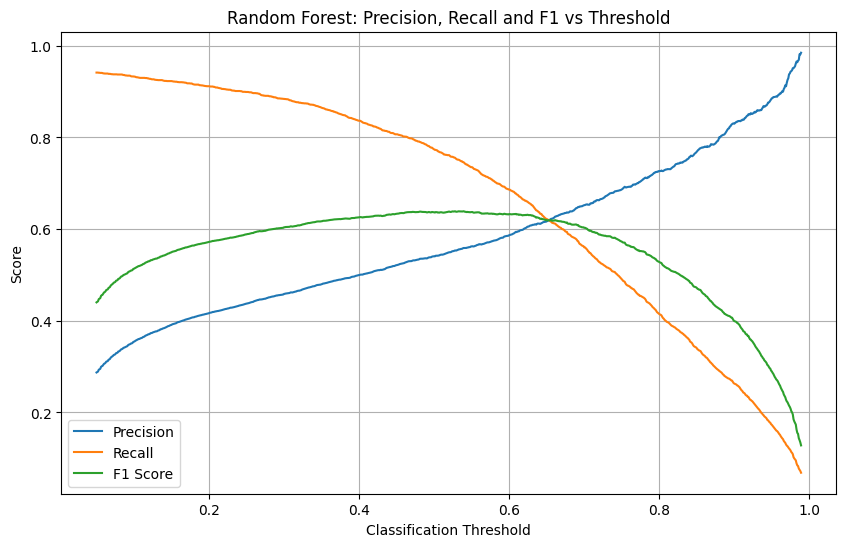

In [113]:
plt.figure(figsize=(10, 6))

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    rf_threshold_df["Threshold"],
    rf_threshold_df["F1 Score"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest: Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

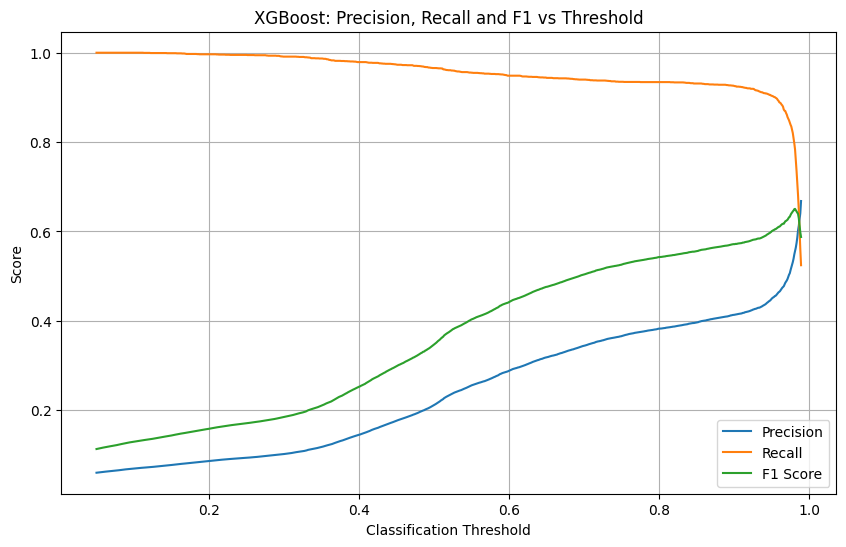

In [114]:
plt.figure(figsize=(10, 6))

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["F1 Score"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost: Precision, Recall and F1 vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [115]:
best_rf = rf_threshold_df.loc[
    rf_threshold_df["F1 Score"].idxmax()
]

best_rf

Threshold    0.539000
Precision    0.558816
Recall       0.746065
F1 Score     0.639005
Name: 489, dtype: float64

In [116]:
best_xgb = xgb_threshold_df.loc[
    xgb_threshold_df["F1 Score"].idxmax()
]

best_xgb

Threshold    0.981000
Precision    0.555969
Recall       0.783491
F1 Score     0.650407
Name: 931, dtype: float64

In [117]:
threshold_comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Best Threshold": [
        best_rf["Threshold"],
        best_xgb["Threshold"]
    ],
    "Precision": [
        best_rf["Precision"],
        best_xgb["Precision"]
    ],
    "Recall": [
        best_rf["Recall"],
        best_xgb["Recall"]
    ],
    "F1 Score": [
        best_rf["F1 Score"],
        best_xgb["F1 Score"]
    ]
})

threshold_comparison

,Model,Best Threshold,Precision,Recall,F1 Score
0,Random Forest,0.539,0.558816,0.746065,0.639005
1,XGBoost,0.981,0.555969,0.783491,0.650407


## Best model is XGBoost

In [118]:
from sklearn.model_selection import RandomizedSearchCV

In [119]:
param_distributions = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40, 50],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

In [120]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [121]:
rf_random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

In [122]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Flatten y_train to 1D array to avoid DataConversionWarning
y_train_1d = y_train.values.ravel()

# Calculate baseline ratio (~122.2)
pos_weight_ratio = y_train.value_counts()[0] / y_train.value_counts()[1]

# Define hyperparameter search space
xgb_param_dist = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 4, 6, 8],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "gamma": [0, 0.1, 0.5],
    # Test full balanced weight as well as milder weights for better probability calibration
    "scale_pos_weight": [1, 10, 25, 50, pos_weight_ratio]
}

xgb_base = XGBClassifier(
    eval_metric="logloss",
    tree_method="hist",  # Fast histogram-based splitting for 1.4M rows
    random_state=42,
    n_jobs=-1            # Parallelize tree building in C++
)

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_dist,
    n_iter=15,                       # 15 combinations x 3 folds = 45 fits
    scoring="average_precision",     # PR-AUC (best metric for 0.81% positive class)
    cv=3,
    random_state=42,
    n_jobs=1,                        # Keep at 1 to prevent disk/memory crash!
    verbose=2
)

xgb_random_search.fit(X_train, y_train_1d)

print("Best Parameters:", xgb_random_search.best_params_)
print("Best CV PR-AUC Score:", xgb_random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.05, max_depth=4, min_child_weight=10, n_estimators=300, scale_pos_weight=50, subsample=0.8; total time=   9.1s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.05, max_depth=4, min_child_weight=10, n_estimators=300, scale_pos_weight=50, subsample=0.8; total time=   8.5s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.05, max_depth=4, min_child_weight=10, n_estimators=300, scale_pos_weight=50, subsample=0.8; total time=   8.5s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.05, max_depth=6, min_child_weight=5, n_estimators=200, scale_pos_weight=10, subsample=1.0; total time=   6.9s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.05, max_depth=6, min_child_weight=5, n_estimators=200, scale_pos_weight=10, subsample=1.0; total time=   6.7s
[CV] END colsample_bytree=0.7, gamma=0, learning_rate=0.05, max_depth=6, min_child_weight=5, n_estim

## This is the best model

In [123]:
best_xgb = xgb_random_search.best_estimator_

In [125]:
tuned_xg_results = evaluate_model(
    best_xgb,
    X_test,
    y_test
)

pd.DataFrame(
    [tuned_xg_results],
    index=["Tuned XGBoost"]
)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Tuned XGBoost,0.99427,0.713415,0.491081,0.581728,0.995137,0.71164


In [126]:
rf_comparison = pd.DataFrame({
    "Original XGBoost": results["XGBoost"],
    "Tuned XGBoost": tuned_xg_results
}).T

rf_comparison

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Original XGBoost,0.970505,0.211490,0.965722,0.346990,0.995071,0.697404
Tuned XGBoost,0.994270,0.713415,0.491081,0.581728,0.995137,0.711640


## Saving the best model

In [127]:
import joblib

In [128]:
joblib.dump(best_xgb,'purchase_intent_model.pkl')

['purchase_intent_model.pkl']

In [130]:
joblib.dump(0.981,'threshold.pkl')

['threshold.pkl']